In [1]:
!pip install -q medmnist

import numpy as np
from medmnist import BloodMNIST

SIZE = 64
SEED = 42
np.random.seed(SEED)

parts = {s: BloodMNIST(split=s, download=True, size=SIZE) for s in ["train", "val", "test"]}

X     = np.concatenate([parts[s].imgs for s in parts])
y     = np.concatenate([parts[s].labels.ravel() for s in parts])
split = np.concatenate([[s] * len(parts[s].labels) for s in parts])

print("X shape:", X.shape)
print("y shape:", y.shape)
print(dict(zip(*np.unique(split, return_counts=True))))

100%|██████████| 156M/156M [01:04<00:00, 2.43MB/s]


X shape: (17092, 64, 64, 3)
y shape: (17092,)
{np.str_('test'): np.int64(3421), np.str_('train'): np.int64(11959), np.str_('val'): np.int64(1712)}


In [2]:
import hashlib
import pandas as pd
import numpy as np

# 1) Compute a fingerprint (md5 hash) of every image's raw pixels
hashes = np.array([
    hashlib.md5(im.tobytes()).hexdigest() for im in X
])

df = pd.DataFrame({
    "hash": hashes,
    "y": y,
    "split": split
})

# 2) Audit overlap groups separately
grouped = df.groupby("hash")

train_val_overlap = 0
train_test_overlap = 0
val_test_overlap = 0
conflict_groups = 0

drop = []

for h, g in grouped:
    splits = set(g["split"])
    labels = set(g["y"])

    if len(splits) > 1:
        if "train" in splits and "val" in splits:
            train_val_overlap += 1
        if "train" in splits and "test" in splits:
            train_test_overlap += 1
        if "val" in splits and "test" in splits:
            val_test_overlap += 1

    if len(labels) > 1:
        conflict_groups += 1

    # Remove only training copies
    if len(splits) > 1 or len(labels) > 1:
        drop.extend(g.index[g["split"] == "train"].tolist())

drop = sorted(set(drop))

# 3) Build the cleaned arrays
keep = np.ones(len(X), dtype=bool)
keep[drop] = False

Xc, yc, sc = X[keep], y[keep], split[keep]

# 4) Print audit results
print("Train-Val overlap groups:", train_val_overlap)
print("Train-Test overlap groups:", train_test_overlap)
print("Val-Test overlap groups:", val_test_overlap)
print("Conflicting-label groups:", conflict_groups)
print("Training images removed:", len(drop))

print("Before:", dict(zip(*np.unique(split, return_counts=True))))
print("After :", dict(zip(*np.unique(sc, return_counts=True))))

Train-Val overlap groups: 3
Train-Test overlap groups: 5
Val-Test overlap groups: 1
Conflicting-label groups: 1
Training images removed: 8
Before: {np.str_('test'): np.int64(3421), np.str_('train'): np.int64(11959), np.str_('val'): np.int64(1712)}
After : {np.str_('test'): np.int64(3421), np.str_('train'): np.int64(11951), np.str_('val'): np.int64(1712)}


In [3]:
import os, time, json, random
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt, seaborn as sns

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

SEED = 42
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
for d in ["models", "results", "figures"]:
    os.makedirs(d, exist_ok=True)

# Label map (integers 0-7), saved for later tasks
label_map = {0: "basophil", 1: "eosinophil", 2: "erythroblast",
             3: "immature granulocytes", 4: "lymphocyte",
             5: "monocyte", 6: "neutrophil", 7: "platelet"}
json.dump(label_map, open("label_map.json", "w"), indent=2)
class_names = [label_map[i] for i in range(8)]
NUM_CLASSES = 8

# Split the CLEANED arrays (official split, duplicates removed from train only)
X_train, y_train = Xc[sc == "train"], yc[sc == "train"]
X_val,   y_val   = Xc[sc == "val"],   yc[sc == "val"]
X_test,  y_test  = Xc[sc == "test"],  yc[sc == "test"]
print("Train/Val/Test:", len(y_train), len(y_val), len(y_test))

# Normalization statistics from the TRAIN split only (no leakage)
pix = X_train.reshape(-1, 3)
mean = pix.mean(axis=0, dtype=np.float64) / 255.0
std = pix.std(axis=0, dtype=np.float64) / 255.0
print("Train mean:", mean.round(4), "| Train std:", std.round(4))
MEAN = torch.tensor(mean, dtype=torch.float32).view(3, 1, 1)
STD = torch.tensor(std, dtype=torch.float32).view(3, 1, 1)
with open("normalization.json", "w") as f:
    json.dump({
        "mean": mean.tolist(),
        "std": std.tolist(),
        "size": SIZE
    }, f, indent=2)

class BloodDataset(Dataset):
    """Uint8 HWC arrays -> normalized CHW tensors. Augmentation only when train=True."""
    def __init__(self, X, y, train=False):
        self.X, self.y, self.train = X, y, train
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        img = torch.from_numpy(self.X[i]).permute(2, 0, 1).float() / 255.0
        if self.train:
            # Flips and 90-degree rotations (cells have no fixed orientation)
            if random.random() < 0.5: img = torch.flip(img, [2])
            if random.random() < 0.5: img = torch.flip(img, [1])
            img = torch.rot90(img, random.randint(0, 3), [1, 2])
            # Mild brightness/contrast only (no hue shift, no grayscale: colour matters here)
            b = random.uniform(-0.08, 0.08)
            c = random.uniform(0.9, 1.1)
            m = img.mean()
            img = ((img - m) * c + m + b).clamp(0, 1)
        img = (img - MEAN) / STD
        return img, int(self.y[i])

BATCH = 128

def make_train_loader():
    # A fresh seeded generator gives every model the same data order
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(BloodDataset(X_train, y_train, train=True), batch_size=BATCH,
                      shuffle=True, generator=g, num_workers=2, pin_memory=True)

val_loader  = DataLoader(BloodDataset(X_val,  y_val),  batch_size=256, num_workers=2, pin_memory=True)
test_loader = DataLoader(BloodDataset(X_test, y_test), batch_size=256, num_workers=2, pin_memory=True)

Device: cuda
Train/Val/Test: 11951 1712 3421
Train mean: [0.7961 0.6596 0.6964] | Train std: [0.2233 0.2546 0.0947]


In [4]:
# weight_c = N / (K * n_c): rare classes get a larger weight in the loss
counts = np.bincount(y_train, minlength=NUM_CLASSES)
class_weights = torch.tensor(len(y_train) / (NUM_CLASSES * counts), dtype=torch.float32)

print(pd.DataFrame({"class": class_names, "train_count": counts,
                    "weight": class_weights.numpy().round(3)}))
np.save("results/class_weights.npy", class_weights.numpy())

                   class  train_count  weight
0               basophil          848   1.762
1             eosinophil         2177   0.686
2           erythroblast         1085   1.377
3  immature granulocytes         2026   0.737
4             lymphocyte          849   1.760
5               monocyte          993   1.504
6             neutrophil         2330   0.641
7               platelet         1643   0.909


In [5]:
import torchvision.models as tvm

PRETRAINED = False   # brief is silent on pretrained weights; confirm with the instructor

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o),
                                 nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(256, num_classes))

    def forward(self, x):
        x = self.pool(self.features(x)).flatten(1)
        return self.head(x)


def build_model(name):
    w = "DEFAULT" if PRETRAINED else None

    if name == "SimpleCNN":
        return SimpleCNN(NUM_CLASSES)

    if name == "ResNet50":
        m = tvm.resnet50(weights=w)

        # Adapt ResNet50 for 64x64 images
        m.conv1 = nn.Conv2d(
            3, 64, kernel_size=3,
            stride=1, padding=1, bias=False
        )
        m.maxpool = nn.Identity()

        m.fc = nn.Linear(
            m.fc.in_features, NUM_CLASSES
        )
        return m

    if name == "DenseNet121":
        m = tvm.densenet121(weights=w)
        m.classifier = nn.Linear(
            m.classifier.in_features, NUM_CLASSES
        )
        return m

    if name == "MobileNetV2":
        m = tvm.mobilenet_v2(weights=w)
        m.classifier[1] = nn.Linear(
            m.classifier[1].in_features, NUM_CLASSES
        )
        return m

    raise ValueError(f"Unknown model: {name}")


def count_params(m):
    return sum(p.numel() for p in m.parameters())


for n in ["SimpleCNN", "ResNet50", "DenseNet121", "MobileNetV2"]:
    m = build_model(n)
    out = m(torch.zeros(2, 3, 64, 64))

    print(
        f"{n:12s} output {tuple(out.shape)} "
        f"| params {count_params(m)/1e6:.2f}M"
    )

SimpleCNN    output (2, 8) | params 0.39M
ResNet50     output (2, 8) | params 23.52M
DenseNet121  output (2, 8) | params 6.96M
MobileNetV2  output (2, 8) | params 2.23M


In [6]:
from sklearn.metrics import f1_score

EPOCHS, PATIENCE = 30, 7
LR, WD = 1e-3, 1e-4
use_amp = device.type == "cuda"

def evaluate(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(xb)
            probs.append(F.softmax(out.float(), dim=1).cpu().numpy())
            ys.append(yb.numpy())
    probs, ys = np.concatenate(probs), np.concatenate(ys)
    return ys, probs.argmax(1), probs

def train_model(name):
    set_seed(SEED)
    model = build_model(name).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    train_loader = make_train_loader()

    best_f1, best_state, wait, hist = -1.0, None, 0, []
    best_epoch = 0
    t0 = time.time()

    for ep in range(1, EPOCHS + 1):
        model.train()
        running = 0.0

        for xb, yb in train_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type=device.type, enabled=use_amp):
                loss = criterion(model(xb), yb)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            running += loss.item() * len(yb)

        yv, pv, _ = evaluate(model, val_loader)
        vf1 = f1_score(yv, pv, average="macro")

        hist.append({
            "epoch": ep,
            "train_loss": running / len(y_train),
            "val_macro_f1": vf1
        })

        print(f"[{name}] epoch {ep:02d} | loss {running/len(y_train):.4f} | val macro-F1 {vf1:.4f}")

        # Early stopping on validation macro-F1
        if vf1 > best_f1:
            best_f1, wait = vf1, 0
            best_epoch = ep
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"[{name}] early stop at epoch {ep}")
                break

    train_time = time.time() - t0
    model.load_state_dict(best_state)

    os.makedirs("models", exist_ok=True)
    path = f"models/{name}_best.pth"
    torch.save(best_state, path)

    info = {
        "model": name,
        "params_M": count_params(model) / 1e6,
        "size_MB": os.path.getsize(path) / 1e6,
        "train_time_min": train_time / 60,
        "epochs_run": len(hist),
        "best_epoch": best_epoch,
        "best_val_macro_f1": best_f1
    }

    return model, pd.DataFrame(hist), info

In [7]:
BASELINES = ["SimpleCNN", "ResNet50", "DenseNet121", "MobileNetV2"]
histories, infos, test_out = {}, {}, {}

for name in BASELINES:
    model, hist, info = train_model(name)
    y_true, y_pred, probs = evaluate(model, test_loader)   # test set used ONLY here

    histories[name], infos[name] = hist, info
    hist.to_csv(f"results/{name}_history.csv", index=False)
    test_out[name] = {"y_true": y_true, "y_pred": y_pred, "probs": probs}

    print(f"==> {name} done: val macro-F1 {info['best_val_macro_f1']:.4f}, "
          f"time {info['train_time_min']:.1f} min\n")

    del model
    torch.cuda.empty_cache()

[SimpleCNN] epoch 01 | loss 0.6169 | val macro-F1 0.8616
[SimpleCNN] epoch 02 | loss 0.2679 | val macro-F1 0.9253
[SimpleCNN] epoch 03 | loss 0.2049 | val macro-F1 0.9265
[SimpleCNN] epoch 04 | loss 0.1658 | val macro-F1 0.6360
[SimpleCNN] epoch 05 | loss 0.1489 | val macro-F1 0.9647
[SimpleCNN] epoch 06 | loss 0.1200 | val macro-F1 0.8891
[SimpleCNN] epoch 07 | loss 0.1104 | val macro-F1 0.8805
[SimpleCNN] epoch 08 | loss 0.1225 | val macro-F1 0.9461
[SimpleCNN] epoch 09 | loss 0.0869 | val macro-F1 0.9568
[SimpleCNN] epoch 10 | loss 0.0887 | val macro-F1 0.9626
[SimpleCNN] epoch 11 | loss 0.0948 | val macro-F1 0.9305
[SimpleCNN] epoch 12 | loss 0.0853 | val macro-F1 0.9440
[SimpleCNN] early stop at epoch 12
==> SimpleCNN done: val macro-F1 0.9647, time 0.5 min

[ResNet50] epoch 01 | loss 0.8244 | val macro-F1 0.7199
[ResNet50] epoch 02 | loss 0.2891 | val macro-F1 0.9101
[ResNet50] epoch 03 | loss 0.2506 | val macro-F1 0.8644
[ResNet50] epoch 04 | loss 0.1762 | val macro-F1 0.8181
[R

SimpleCNN
                       precision    recall  f1-score   support

             basophil     0.9714    0.9754    0.9734       244
           eosinophil     0.9968    0.9984    0.9976       624
         erythroblast     0.8902    0.9904    0.9376       311
immature granulocytes     0.9115    0.9430    0.9270       579
           lymphocyte     0.9903    0.8395    0.9087       243
             monocyte     0.9247    0.9085    0.9165       284
           neutrophil     0.9800    0.9565    0.9681       666
             platelet     0.9979    1.0000    0.9989       470

             accuracy                         0.9600      3421
            macro avg     0.9579    0.9514    0.9535      3421
         weighted avg     0.9613    0.9600    0.9599      3421



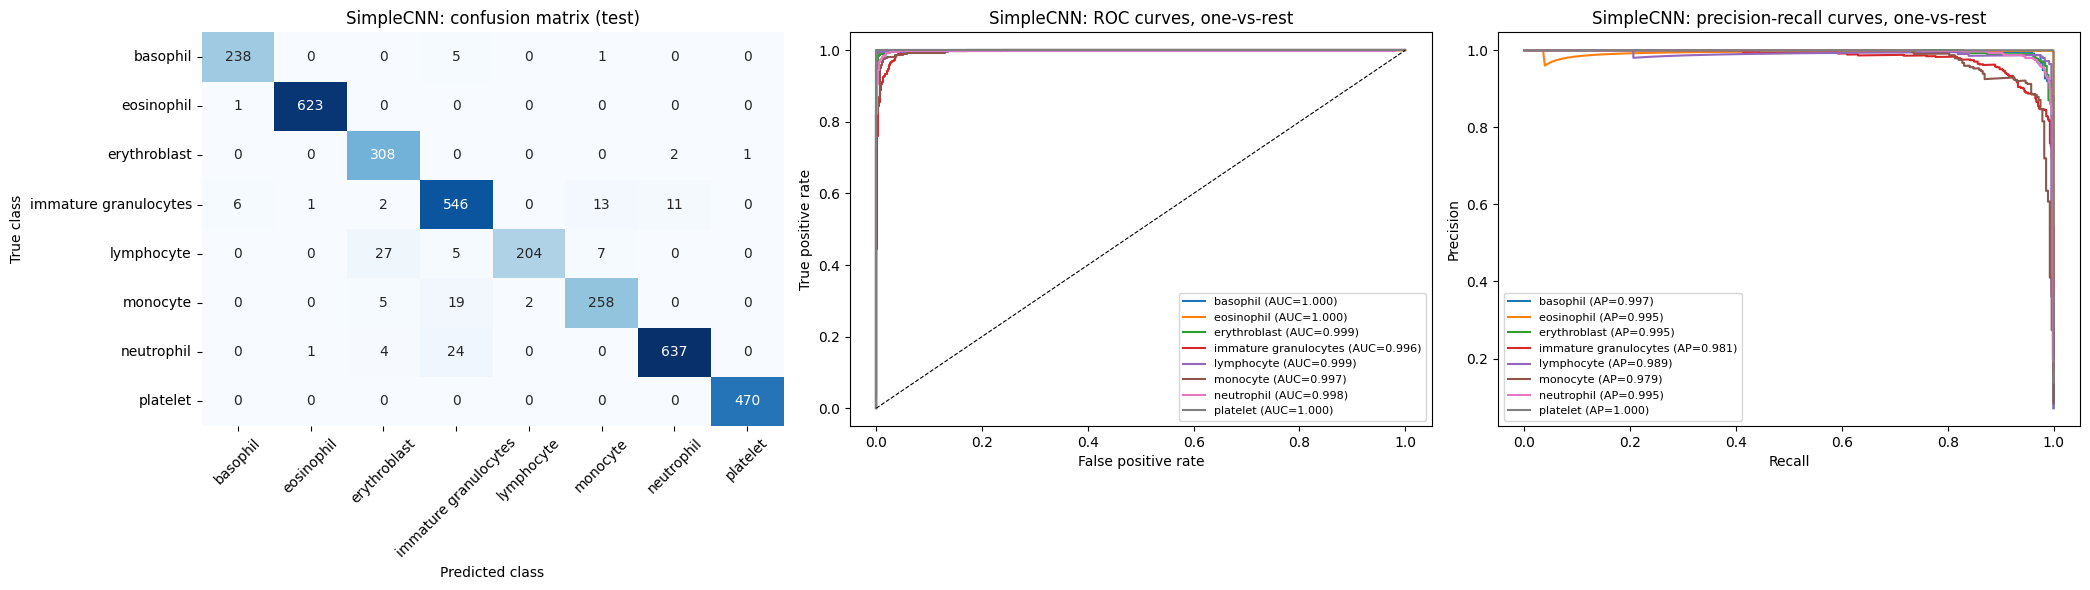

ResNet50
                       precision    recall  f1-score   support

             basophil     0.9958    0.9754    0.9855       244
           eosinophil     0.9968    0.9984    0.9976       624
         erythroblast     0.9360    0.9871    0.9609       311
immature granulocytes     0.9309    0.9534    0.9420       579
           lymphocyte     0.9833    0.9712    0.9772       243
             monocyte     0.9883    0.8908    0.9370       284
           neutrophil     0.9688    0.9775    0.9731       666
             platelet     1.0000    0.9957    0.9979       470

             accuracy                         0.9728      3421
            macro avg     0.9750    0.9687    0.9714      3421
         weighted avg     0.9734    0.9728    0.9728      3421



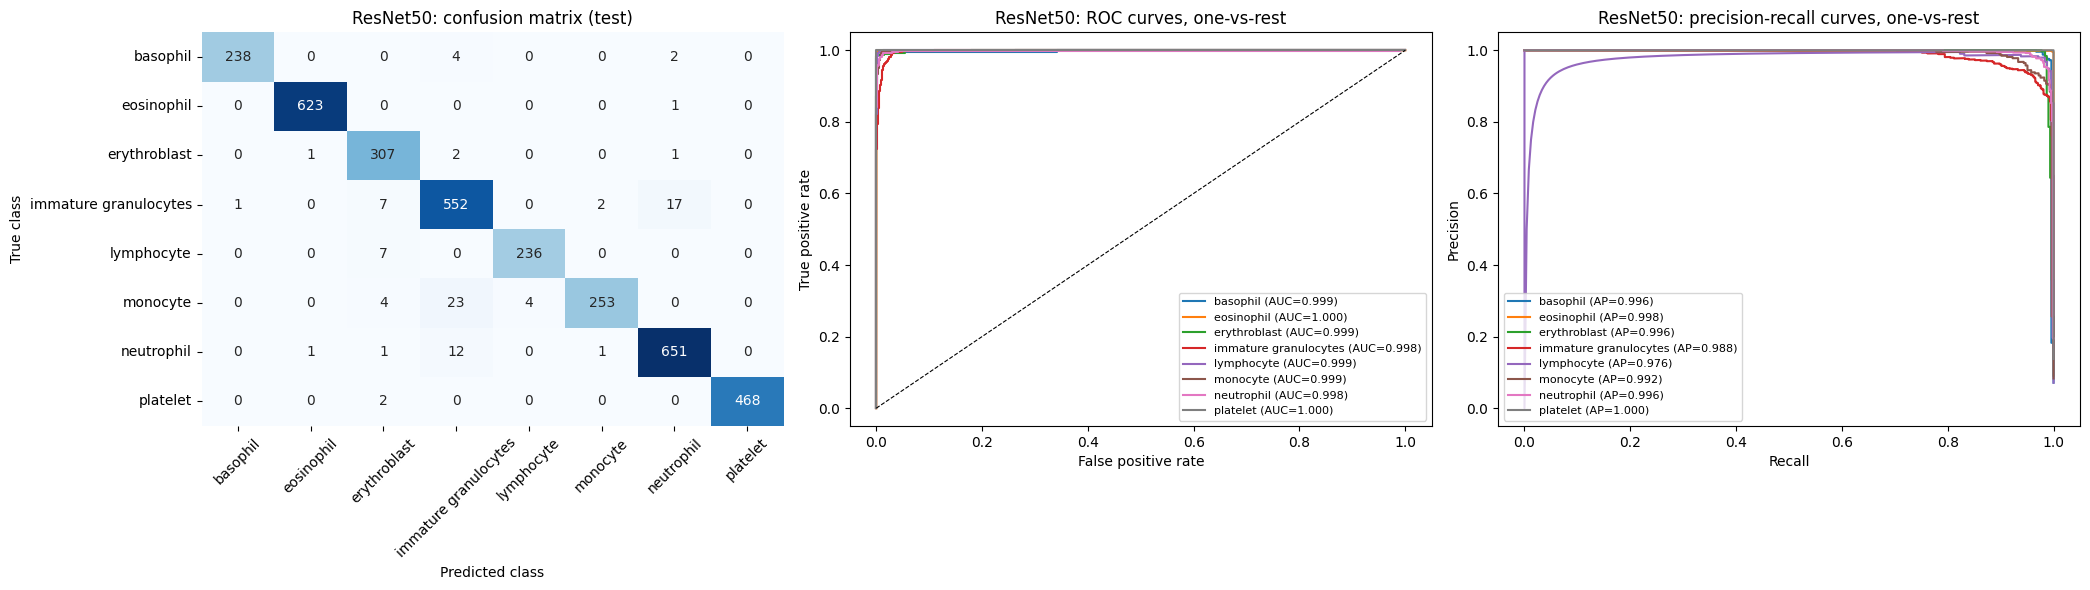

DenseNet121
                       precision    recall  f1-score   support

             basophil     0.9449    0.9836    0.9639       244
           eosinophil     0.9984    0.9984    0.9984       624
         erythroblast     0.9965    0.9260    0.9600       311
immature granulocytes     0.9299    0.9396    0.9347       579
           lymphocyte     0.9830    0.9506    0.9665       243
             monocyte     0.9161    0.9613    0.9381       284
           neutrophil     0.9760    0.9775    0.9767       666
             platelet     1.0000    0.9979    0.9989       470

             accuracy                         0.9702      3421
            macro avg     0.9681    0.9669    0.9672      3421
         weighted avg     0.9708    0.9702    0.9703      3421



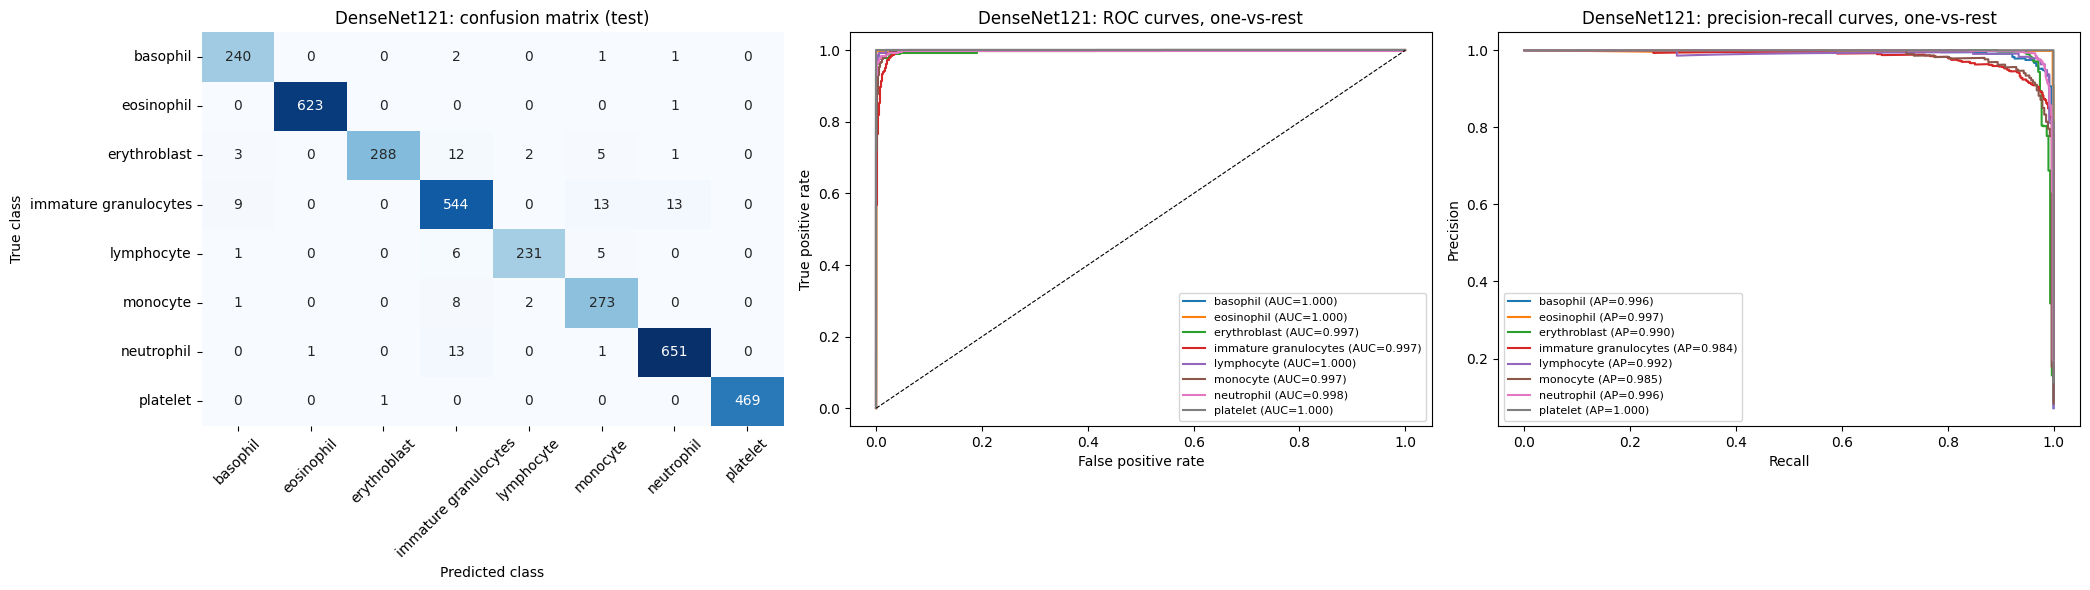

MobileNetV2
                       precision    recall  f1-score   support

             basophil     0.9520    0.9754    0.9636       244
           eosinophil     0.9968    0.9968    0.9968       624
         erythroblast     0.9838    0.9775    0.9806       311
immature granulocytes     0.9739    0.9033    0.9373       579
           lymphocyte     0.9676    0.9835    0.9755       243
             monocyte     0.9238    0.9824    0.9522       284
           neutrophil     0.9604    0.9835    0.9718       666
             platelet     1.0000    1.0000    1.0000       470

             accuracy                         0.9734      3421
            macro avg     0.9698    0.9753    0.9722      3421
         weighted avg     0.9738    0.9734    0.9732      3421



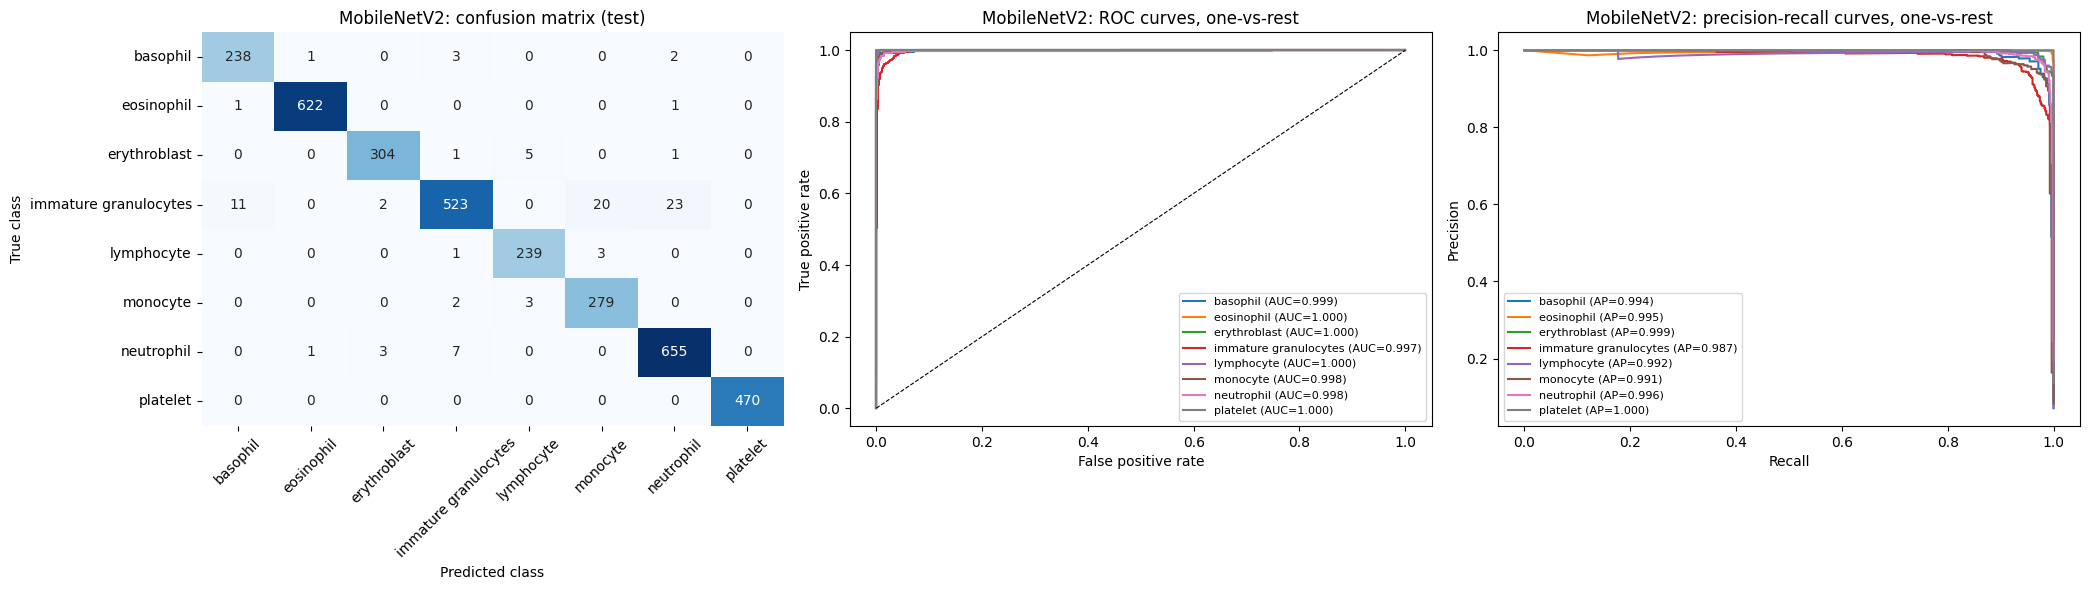

,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,basophil_precision,basophil_recall,basophil_f1,...,lymphocyte_f1,monocyte_precision,monocyte_recall,monocyte_f1,neutrophil_precision,neutrophil_recall,neutrophil_f1,platelet_precision,platelet_recall,platelet_f1
SimpleCNN,0.9600,0.9579,0.9514,0.9535,0.9613,0.9600,0.9599,0.9714,0.9754,0.9734,...,0.9087,0.9247,0.9085,0.9165,0.9800,0.9565,0.9681,0.9979,1.0000,0.9989
ResNet50,0.9728,0.9750,0.9687,0.9714,0.9734,0.9728,0.9728,0.9958,0.9754,0.9855,...,0.9772,0.9883,0.8908,0.9370,0.9688,0.9775,0.9731,1.0000,0.9957,0.9979
DenseNet121,0.9702,0.9681,0.9669,0.9672,0.9708,0.9702,0.9703,0.9449,0.9836,0.9639,...,0.9665,0.9161,0.9613,0.9381,0.9760,0.9775,0.9767,1.0000,0.9979,0.9989
MobileNetV2,0.9734,0.9698,0.9753,0.9722,0.9738,0.9734,0.9732,0.9520,0.9754,0.9636,...,0.9755,0.9238,0.9824,0.9522,0.9604,0.9835,0.9718,1.0000,1.0000,1.0000


,SimpleCNN,ResNet50,DenseNet121,MobileNetV2
basophil,0.9754,0.9754,0.9836,0.9754
eosinophil,0.9984,0.9984,0.9984,0.9968
erythroblast,0.9904,0.9871,0.9260,0.9775
immature granulocytes,0.9430,0.9534,0.9396,0.9033
lymphocyte,0.8395,0.9712,0.9506,0.9835
monocyte,0.9085,0.8908,0.9613,0.9824
neutrophil,0.9565,0.9775,0.9775,0.9835
platelet,1.0000,0.9957,0.9979,1.0000


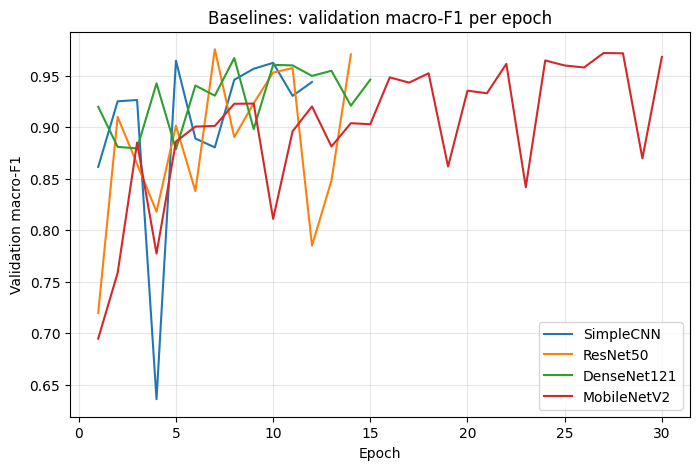

In [8]:
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score, roc_auc_score
)
from sklearn.preprocessing import label_binarize

recall_rows = {}
metric_rows = {}

for name in BASELINES:
    yt, yp, pr = test_out[name]["y_true"], test_out[name]["y_pred"], test_out[name]["probs"]

    # Binarize labels for ROC and PR curves
    Y_bin = label_binarize(yt, classes=list(range(NUM_CLASSES)))

    print("=" * 70, f"\n{name}\n", "=" * 70)

    rep = classification_report(
        yt, yp, target_names=class_names, digits=4, output_dict=True
    )
    print(classification_report(
        yt, yp, target_names=class_names, digits=4
    ))

    # Overall metrics
    metric_rows[name] = {
        "accuracy": rep["accuracy"],
        "macro_precision": rep["macro avg"]["precision"],
        "macro_recall": rep["macro avg"]["recall"],
        "macro_f1": rep["macro avg"]["f1-score"],
        "weighted_precision": rep["weighted avg"]["precision"],
        "weighted_recall": rep["weighted avg"]["recall"],
        "weighted_f1": rep["weighted avg"]["f1-score"]
    }

    # Per-class metrics
    for c in class_names:
        metric_rows[name][f"{c}_precision"] = rep[c]["precision"]
        metric_rows[name][f"{c}_recall"] = rep[c]["recall"]
        metric_rows[name][f"{c}_f1"] = rep[c]["f1-score"]

    recall_rows[name] = {c: rep[c]["recall"] for c in class_names}

    fig, axes = plt.subplots(1, 3, figsize=(21, 6))

    # Confusion Matrix
    cm = confusion_matrix(yt, yp)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names,
        ax=axes[0], cbar=False
    )
    axes[0].set_title(f"{name}: confusion matrix (test)")
    axes[0].set_xlabel("Predicted class")
    axes[0].set_ylabel("True class")
    axes[0].tick_params(axis="x", rotation=45)

    # ROC Curves
    for c in range(NUM_CLASSES):
        fpr, tpr, _ = roc_curve(Y_bin[:, c], pr[:, c])
        axes[1].plot(
            fpr, tpr,
            label=f"{class_names[c]} (AUC={auc(fpr, tpr):.3f})"
        )

    axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[1].set_title(f"{name}: ROC curves, one-vs-rest")
    axes[1].set_xlabel("False positive rate")
    axes[1].set_ylabel("True positive rate")
    axes[1].legend(fontsize=8, loc="lower right")

    # Precision-Recall Curves
    for c in range(NUM_CLASSES):
        p, r, _ = precision_recall_curve(Y_bin[:, c], pr[:, c])
        axes[2].plot(
            r, p,
            label=f"{class_names[c]} (AP={average_precision_score(Y_bin[:, c], pr[:, c]):.3f})"
        )

    axes[2].set_title(f"{name}: precision-recall curves, one-vs-rest")
    axes[2].set_xlabel("Recall")
    axes[2].set_ylabel("Precision")
    axes[2].legend(fontsize=8, loc="lower left")

    plt.tight_layout()
    plt.savefig(f"figures/{name}_cm_roc_pr.png", dpi=200, bbox_inches="tight")
    plt.show()


# Save overall and per-class metrics
metrics_df = pd.DataFrame(metric_rows).T.round(4)
display(metrics_df)
metrics_df.to_csv("results/baselines_full_metrics.csv")

# Per-class recall across baselines
recall_df = pd.DataFrame(recall_rows).round(4)
display(recall_df)
recall_df.to_csv("results/baselines_per_class_recall.csv")


# Training curves (validation macro-F1 per epoch)
plt.figure(figsize=(8, 5))

for name in BASELINES:
    plt.plot(
        histories[name]["epoch"],
        histories[name]["val_macro_f1"],
        label=name
    )

plt.title("Baselines: validation macro-F1 per epoch")
plt.xlabel("Epoch")
plt.ylabel("Validation macro-F1")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("figures/baselines_val_curves.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

rows = []

for name in BASELINES:
    yt, yp, pr = test_out[name]["y_true"], test_out[name]["y_pred"], test_out[name]["probs"]

    rows.append({
        **infos[name],
        "test_acc": accuracy_score(yt, yp),
        "macro_precision": precision_score(yt, yp, average="macro"),
        "macro_recall": recall_score(yt, yp, average="macro"),
        "macro_f1": f1_score(yt, yp, average="macro"),
        "weighted_f1": f1_score(yt, yp, average="weighted"),
        "macro_auc_ovr": roc_auc_score(yt, pr, multi_class="ovr", average="macro"),
    })

results = pd.DataFrame(rows).sort_values(
    "best_val_macro_f1", ascending=False
).reset_index(drop=True)

display(results.round(4))

print("Best baseline (highest validation macro-F1):", results.loc[0, "model"])

# Save everything needed by notebook 2 and Task 3
results.to_csv("results/baselines_results.csv", index=False)

np.savez_compressed(
    "results/baselines_test_predictions.npz",
    **{f"{n}_{k}": v for n in BASELINES for k, v in test_out[n].items()}
)

np.savez_compressed("bloodmnist_64_clean.npz", X=Xc, y=yc, split=sc)

print("Saved: results/*.csv, results/*.npz, bloodmnist_64_clean.npz, models/*.pth, label_map.json")

,model,params_M,size_MB,train_time_min,epochs_run,best_epoch,best_val_macro_f1,test_acc,macro_precision,macro_recall,macro_f1,weighted_f1,macro_auc_ovr
0,ResNet50,23.5167,94.3769,13.8350,14,7,0.9758,0.9728,0.9750,0.9687,0.9714,0.9728,0.9989
1,MobileNetV2,2.2341,9.1708,2.2168,30,27,0.9721,0.9734,0.9698,0.9753,0.9722,0.9732,0.9990
2,DenseNet121,6.9621,28.4234,2.2477,15,8,0.9672,0.9702,0.9681,0.9669,0.9672,0.9703,0.9985
3,SimpleCNN,0.3914,1.5792,0.4912,12,5,0.9647,0.9600,0.9579,0.9514,0.9535,0.9599,0.9986


Best baseline (highest validation macro-F1): ResNet50
Saved: results/*.csv, results/*.npz, bloodmnist_64_clean.npz, models/*.pth, label_map.json
